# 🖼️ CIFAR-10 Image Classification với KNN

## Pipeline: HOG + Color Histogram Features → PCA → K-Nearest Neighbors

### Tham khảo từ các bài báo khoa học tiêu biểu:
- **Krizhevsky, A. (2009)** – *Learning Multiple Layers of Features from Tiny Images* (CIFAR-10 original paper)
- **Dalal & Triggs (2005)** – *Histograms of Oriented Gradients for Human Detection* (HOG feature descriptor)
- **Cover & Hart (1967)** – *Nearest Neighbor Pattern Classification* (KNN algorithm)
- **Lowe, D.G. (2004)** – *Distinctive Image Features from Scale-Invariant Keypoints* (SIFT, động lực cho HOG)
- **Zhang et al. (2006)** – *SVM-KNN: Discriminative Nearest Neighbor Classification for Visual Category Recognition*

**Pipeline tổng quan:**
```
CIFAR-10 Raw Images (32×32×3)
        ↓
Feature Extraction
  ├── HOG (Histogram of Oriented Gradients) — capture cạnh & hình dạng
  └── Color Histogram (HSV) — capture màu sắc đặc trưng
        ↓
Feature Normalization (L2)
        ↓
PCA Dimensionality Reduction
        ↓
KNN Classification (k tối ưu qua Cross-Validation)
        ↓
Evaluation & Visualization
```

## 1. Import thư viện

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline

from skimage.feature import hog
from skimage.color import rgb2hsv
from skimage import exposure
import tensorflow as tf 
from tensorflow.keras import datasets 
import time
import os
import pickle

I0000 00:00:1779809508.856081   59370 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 2. Tải và khám phá CIFAR-10 Dataset

In [7]:
# Tên các lớp CIFAR-10
CLASS_NAMES = [
    'airplane', 'automobile', 'bird', 'cat', 'deer',
    'dog', 'frog', 'horse', 'ship', 'truck'
]
CLASS_COLORS = plt.cm.tab10(np.linspace(0, 1, 10))
t0 = time.time()

# Tải dataset (pixel values 0-255)
(x_train, y_train), (x_test, y_test) = datasets.cifar10.load_data()

print(f"✅ Tải xong trong {time.time()-t0:.1f}s")
print(f"   X shape: {x_train.shape}  (60000 ảnh × 3072 pixel=32×32×3)")
print(f"   y shape: {y_test.shape}")
print(f"   Classes: {np.unique(y_train)} → {CLASS_NAMES}")

✅ Tải xong trong 1.9s
   X shape: (50000, 32, 32, 3)  (60000 ảnh × 3072 pixel=32×32×3)
   y shape: (10000, 1)
   Classes: [0 1 2 3 4 5 6 7 8 9] → ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


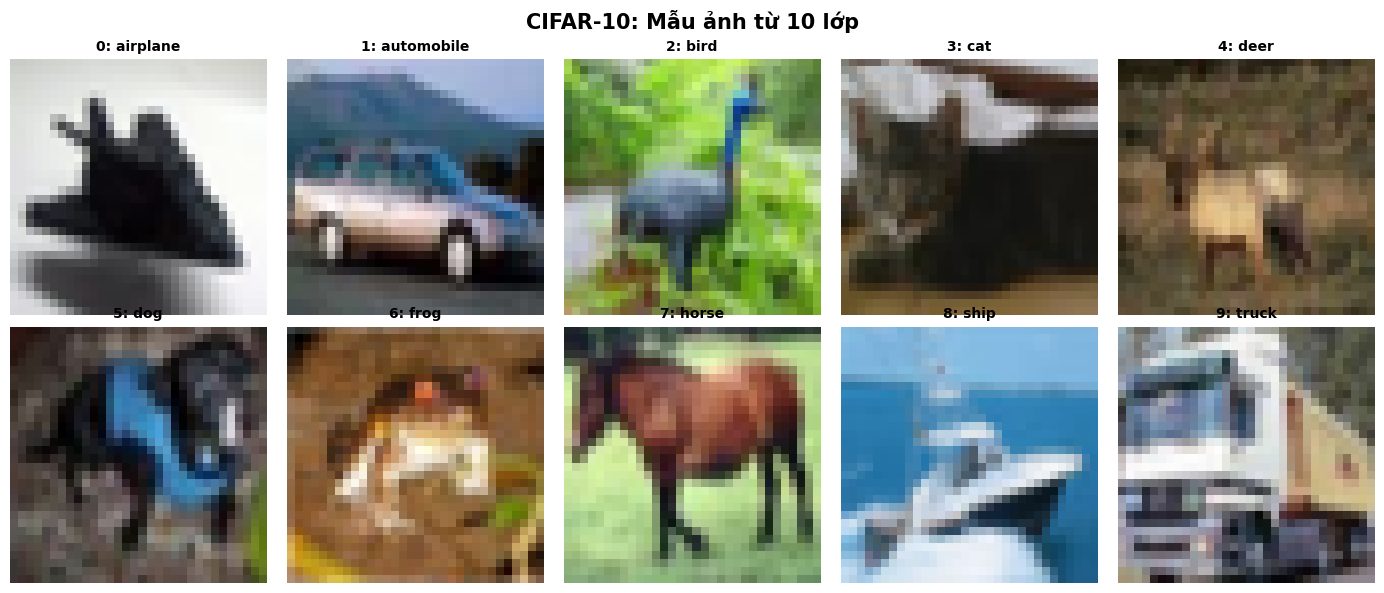

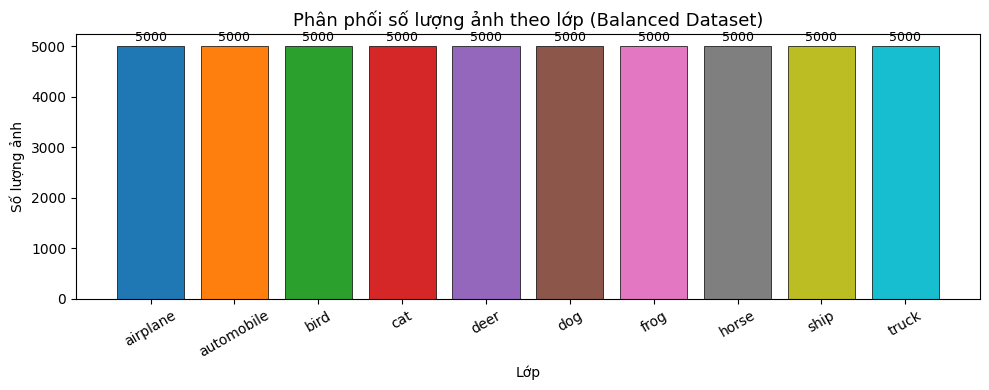

In [8]:
# Visualize mẫu từ mỗi class
fig, axes = plt.subplots(2, 5, figsize=(14, 6))
fig.suptitle('CIFAR-10: Mẫu ảnh từ 10 lớp', fontsize=15, fontweight='bold')

for i, (ax, cls_name) in enumerate(zip(axes.flat, CLASS_NAMES)):
    idx = np.where(y_train == i)[0][0]
    ax.imshow(x_train[idx])
    ax.set_title(f'{i}: {cls_name}', fontsize=10, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

# Phân phối classes
fig, ax = plt.subplots(figsize=(10, 4))
counts = [np.sum(y_train == i) for i in range(10)]
bars = ax.bar(CLASS_NAMES, counts, color=CLASS_COLORS, edgecolor='black', linewidth=0.5)
ax.set_title('Phân phối số lượng ảnh theo lớp (Balanced Dataset)', fontsize=13)
ax.set_ylabel('Số lượng ảnh')
ax.set_xlabel('Lớp')
for bar, count in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
            str(count), ha='center', va='bottom', fontsize=9)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 3. Feature Extraction: HOG + Color Histogram

### 3.1 Tại sao HOG?

> **Dalal & Triggs (2005)** chứng minh HOG nắm bắt cấu trúc cục bộ (cạnh, texture) hiệu quả hơn pixel thô.  
> HOG chia ảnh thành các cell, tính histogram hướng gradient trong mỗi cell, rồi normalize theo block.  
> Điều này giúp feature **bất biến với thay đổi ánh sáng** nhỏ.

### 3.2 Tại sao Color Histogram?

> HOG chỉ làm việc với thông tin hình dạng (grayscale). CIFAR-10 có nhiều lớp phân biệt bởi màu sắc  
> (ví dụ: frog xanh lá, sky/airplane xanh dương). **Color Histogram trong không gian HSV**  
> bổ sung thông tin màu sắc mà HOG bỏ qua. *(Sermanet & LeCun, 2012)*

In [9]:
def extract_hog_features(img_rgb):
    """
    Trích xuất HOG features từ ảnh RGB.
    
    Tham số theo Dalal & Triggs (2005):
    - orientations=9: 9 bins hướng (0°-180°)
    - pixels_per_cell=(4,4): cell nhỏ cho ảnh 32×32
    - cells_per_block=(2,2): normalize theo 2×2 cells
    - channel_axis=-1: xử lý 3 channels RGB
    """
    feat = hog(
        img_rgb,
        orientations=9,
        pixels_per_cell=(4, 4),
        cells_per_block=(2, 2),
        channel_axis=-1,
        feature_vector=True
    )
    return feat


def extract_color_histogram(img_rgb, n_bins=32):
    """
    Trích xuất Color Histogram trong không gian HSV.
    
    HSV tách biệt thông tin màu (Hue) khỏi độ sáng (Value),
    giúp feature ổn định hơn khi thay đổi ánh sáng.
    """
    img_hsv = rgb2hsv(img_rgb)  # → [0,1]
    hist_h, _ = np.histogram(img_hsv[:,:,0], bins=n_bins, range=(0,1))
    hist_s, _ = np.histogram(img_hsv[:,:,1], bins=n_bins, range=(0,1))
    hist_v, _ = np.histogram(img_hsv[:,:,2], bins=n_bins, range=(0,1))
    hist = np.concatenate([hist_h, hist_s, hist_v]).astype(np.float32)
    hist /= (hist.sum() + 1e-7)  # normalize thành probability distribution
    return hist


def extract_combined_features(img_rgb):
    """Kết hợp HOG + Color Histogram thành vector đặc trưng."""
    hog_feat   = extract_hog_features(img_rgb)
    color_feat = extract_color_histogram(img_rgb)
    return np.concatenate([hog_feat, color_feat])


# Kiểm tra kích thước feature
sample = x_train[0]
hog_f  = extract_hog_features(sample)
col_f  = extract_color_histogram(sample)
comb_f = extract_combined_features(sample)

print("📐 Kích thước feature vectors:")
print(f"   HOG features:           {hog_f.shape[0]:>5} chiều")
print(f"   Color Histogram (HSV):  {col_f.shape[0]:>5} chiều  (32 bins × 3 channels)")
print(f"   Combined (HOG + Color): {comb_f.shape[0]:>5} chiều  ← vector cuối cùng")

📐 Kích thước feature vectors:
   HOG features:            1764 chiều
   Color Histogram (HSV):     96 chiều  (32 bins × 3 channels)
   Combined (HOG + Color):  1860 chiều  ← vector cuối cùng


TypeError: only integer scalar arrays can be converted to a scalar index

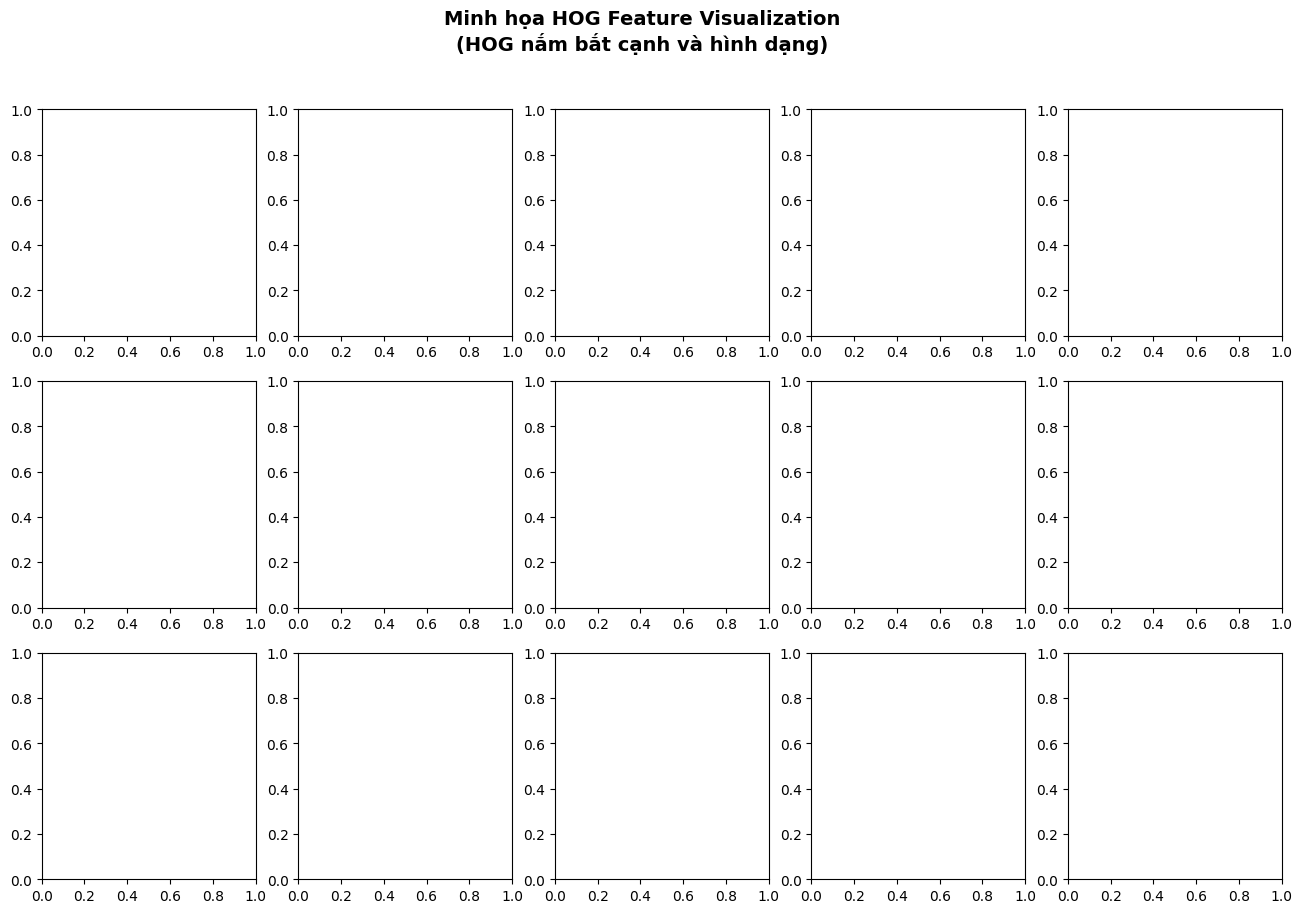

In [10]:
# Visualize HOG trên một vài ảnh mẫu
fig, axes = plt.subplots(3, 5, figsize=(16, 10))
fig.suptitle('Minh họa HOG Feature Visualization\n(HOG nắm bắt cạnh và hình dạng)', 
             fontsize=14, fontweight='bold')

sample_indices = [np.where(y_train == i)[0][0] for i in range(5)]

for col, idx in enumerate(sample_indices):
    img = x_train[idx]
    cls = CLASS_NAMES[y_train[idx]]
    
    # Original
    axes[0, col].imshow(img)
    axes[0, col].set_title(f'Original\n{cls}', fontsize=9)
    axes[0, col].axis('off')
    
    # HOG visualization
    _, hog_img = hog(img, orientations=9, pixels_per_cell=(4,4),
                     cells_per_block=(2,2), channel_axis=-1,
                     visualize=True, feature_vector=True)
    hog_img_eq = exposure.rescale_intensity(hog_img, in_range=(0, 0.1))
    axes[1, col].imshow(hog_img_eq, cmap='hot')
    axes[1, col].set_title('HOG', fontsize=9)
    axes[1, col].axis('off')
    
    # Color histogram
    hsv = rgb2hsv(img)
    hist_h, _ = np.histogram(hsv[:,:,0], bins=32, range=(0,1))
    axes[2, col].bar(range(32), hist_h, color='purple', alpha=0.7)
    axes[2, col].set_title('Hue Histogram', fontsize=9)
    axes[2, col].set_xticks([])

axes[0,0].set_ylabel('Ảnh gốc', fontsize=10, fontweight='bold')
axes[1,0].set_ylabel('HOG map', fontsize=10, fontweight='bold')
axes[2,0].set_ylabel('Hue hist', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

In [ ]:
print("⚙️  Đang trích xuất features cho tập TRAIN...")
t0 = time.time()
X_train_feat = np.array([extract_combined_features(img) for img in X_train_imgs])
print(f"   Train features: {X_train_feat.shape}  ({time.time()-t0:.1f}s)")

print("⚙️  Đang trích xuất features cho tập TEST...")
t0 = time.time()
X_test_feat  = np.array([extract_combined_features(img) for img in X_test_imgs])
print(f"   Test features:  {X_test_feat.shape}  ({time.time()-t0:.1f}s)")

print("✅ Trích xuất features hoàn tất!")

## 5. Feature Normalization

> KNN dựa trên khoảng cách Euclidean — rất nhạy cảm với scale của features.  
> **L2 normalization** đưa mỗi vector về đơn vị cầu (unit sphere),  
> đảm bảo HOG features và Color Histogram đóng góp công bằng.  
> *(Best practice được khuyến nghị trong Zhang et al., 2006)*

In [ ]:
# L2 Normalization
X_train_norm = normalize(X_train_feat, norm='l2')
X_test_norm  = normalize(X_test_feat,  norm='l2')

print(f"L2 Norm của vector đầu tiên sau normalization: {np.linalg.norm(X_train_norm[0]):.6f}")
print(f"✅ L2 normalization hoàn tất!")

# Visualize feature distribution trước và sau normalization
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(X_train_feat[:100].flatten(), bins=50, color='steelblue', alpha=0.7, edgecolor='black')
axes[0].set_title('Feature Distribution\nTRƯỚC Normalization', fontsize=12)
axes[0].set_xlabel('Giá trị feature'); axes[0].set_ylabel('Tần số')

axes[1].hist(X_train_norm[:100].flatten(), bins=50, color='darkorange', alpha=0.7, edgecolor='black')
axes[1].set_title('Feature Distribution\nSAU L2 Normalization', fontsize=12)
axes[1].set_xlabel('Giá trị feature'); axes[1].set_ylabel('Tần số')

plt.tight_layout()
plt.show()

## 6. PCA Dimensionality Reduction

> **Curse of Dimensionality**: KNN hoạt động kém khi số chiều cao vì khoảng cách Euclidean  
> trở nên vô nghĩa trong không gian nhiều chiều *(Bellman, 1961)*.  
> PCA giảm chiều xuống ~95% variance được giữ lại, loại bỏ noise và tăng tốc KNN.
> Kết hợp PCA + KNN là cách tiếp cận chuẩn trong các benchmark *(Zhang et al., 2006)*.

In [ ]:
# Tìm số components giữ 95% variance
pca_analysis = PCA(n_components=min(200, X_train_norm.shape[1])).fit(X_train_norm)
explained_var_cumsum = np.cumsum(pca_analysis.explained_variance_ratio_)

n_95  = np.argmax(explained_var_cumsum >= 0.95) + 1
n_99  = np.argmax(explained_var_cumsum >= 0.99) + 1

# Visualize scree plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scree plot
axes[0].plot(range(1, len(pca_analysis.explained_variance_ratio_)+1),
             pca_analysis.explained_variance_ratio_, 'b-o', markersize=3)
axes[0].set_xlabel('Principal Component'); axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Scree Plot')
axes[0].set_xlim(0, 100)

# Cumulative variance
axes[1].plot(range(1, len(explained_var_cumsum)+1), explained_var_cumsum * 100, 
             'darkorange', linewidth=2)
axes[1].axhline(y=95, color='red', linestyle='--', alpha=0.7, label='95% variance')
axes[1].axhline(y=99, color='purple', linestyle='--', alpha=0.7, label='99% variance')
axes[1].axvline(x=n_95, color='red', linestyle=':', alpha=0.5)
axes[1].axvline(x=n_99, color='purple', linestyle=':', alpha=0.5)
axes[1].text(n_95+2, 60, f'{n_95} PCs\n(95%)', color='red', fontsize=9)
axes[1].text(n_99+2, 45, f'{n_99} PCs\n(99%)', color='purple', fontsize=9)
axes[1].set_xlabel('Số Principal Components'); axes[1].set_ylabel('Cumulative Explained Variance (%)')
axes[1].set_title('Cumulative Explained Variance')
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"📊 Kết quả PCA Analysis:")
print(f"   Chiều ban đầu:  {X_train_norm.shape[1]}")
print(f"   Để giữ 95% var: {n_95} components")
print(f"   Để giữ 99% var: {n_99} components")

# Chọn n_95 cho balance accuracy/speed
N_COMPONENTS = n_95
print(f"\n✅ Chọn N_COMPONENTS = {N_COMPONENTS} (giữ 95% variance)")

In [ ]:
# Fit và transform PCA
pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_norm)
X_test_pca  = pca.transform(X_test_norm)

print(f"Shape sau PCA — Train: {X_train_pca.shape}, Test: {X_test_pca.shape}")
print(f"Variance được giữ lại: {pca.explained_variance_ratio_.sum()*100:.2f}%")

# 2D PCA visualization (2 components đầu)
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_vis = pca_2d.fit_transform(X_train_norm)

fig, ax = plt.subplots(figsize=(10, 8))
for i, (cls_name, color) in enumerate(zip(CLASS_NAMES, CLASS_COLORS)):
    mask = y_train == i
    ax.scatter(X_vis[mask, 0], X_vis[mask, 1], 
               c=[color], label=cls_name, alpha=0.4, s=15)

ax.set_title('PCA 2D Visualization của CIFAR-10 Features\n(2 principal components đầu tiên)', fontsize=13)
ax.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.1f}% variance)')
ax.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.1f}% variance)')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. KNN: Chọn k tối ưu qua Cross-Validation

> Giá trị k cần được chọn cẩn thận:  
> - k quá nhỏ: **overfitting** (nhạy cảm với noise)  
> - k quá lớn: **underfitting** (mất ranh giới quyết định)  
> **5-fold Stratified Cross-Validation** là tiêu chuẩn được dùng rộng rãi *(Kohavi, 1995)*.

In [ ]:
# Cross-validation để chọn k tối ưu
k_candidates = [1, 3, 5, 7, 10, 15, 20]
cv_scores = {}

print("🔍 Cross-Validation để chọn k tối ưu (5-fold Stratified CV)...")
print("-" * 45)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for k in k_candidates:
    t0 = time.time()
    knn = KNeighborsClassifier(
        n_neighbors=k,
        metric='euclidean',
        n_jobs=-1      # dùng tất cả CPU cores
    )
    scores = cross_val_score(knn, X_train_pca, y_train, cv=skf, scoring='accuracy', n_jobs=-1)
    cv_scores[k] = scores
    print(f"  k={k:2d}: mean={scores.mean():.4f} ± {scores.std():.4f}  ({time.time()-t0:.1f}s)")

best_k = max(cv_scores, key=lambda k: cv_scores[k].mean())
print(f"\n🏆 K tối ưu: k = {best_k}  (CV accuracy = {cv_scores[best_k].mean():.4f})")

In [ ]:
# Vẽ CV accuracy vs k
fig, ax = plt.subplots(figsize=(10, 5))

means = [cv_scores[k].mean() for k in k_candidates]
stds  = [cv_scores[k].std()  for k in k_candidates]

ax.errorbar(k_candidates, means, yerr=stds, 
            fmt='b-o', markersize=8, capsize=5, linewidth=2, label='CV Accuracy ± std')
ax.axvline(x=best_k, color='red', linestyle='--', linewidth=2, label=f'Best k={best_k}')
ax.scatter([best_k], [cv_scores[best_k].mean()], 
           color='red', s=120, zorder=5)

ax.set_xlabel('k (số láng giềng)', fontsize=12)
ax.set_ylabel('Cross-Validation Accuracy', fontsize=12)
ax.set_title('KNN: Chọn k tối ưu qua 5-Fold Stratified Cross-Validation', fontsize=13)
ax.set_xticks(k_candidates)
ax.legend(fontsize=11)
ax.grid(alpha=0.3)

for k, m in zip(k_candidates, means):
    ax.annotate(f'{m:.3f}', (k, m), textcoords="offset points",
                xytext=(0, 10), ha='center', fontsize=9)

plt.tight_layout()
plt.show()

## 8. Train mô hình KNN cuối cùng & Đánh giá

In [ ]:
# Train với k tối ưu trên toàn tập train
print(f"🚀 Training KNN với k={best_k}...")
t0 = time.time()

knn_final = KNeighborsClassifier(
    n_neighbors=best_k,
    metric='euclidean',
    n_jobs=-1
)
knn_final.fit(X_train_pca, y_train)
print(f"✅ Training xong! ({time.time()-t0:.2f}s)")

# Predict trên tập test
print("🔮 Đang predict tập test...")
t0 = time.time()
y_pred = knn_final.predict(X_test_pca)
print(f"✅ Predict xong! ({time.time()-t0:.2f}s)")

# Kết quả tổng thể
test_acc = accuracy_score(y_test, y_pred)
print(f"\n{'='*50}")
print(f"  🎯 TEST ACCURACY: {test_acc*100:.2f}%")
print(f"{'='*50}")

In [ ]:
# Classification Report chi tiết
print("📊 Classification Report chi tiết:")
print("=" * 65)
print(classification_report(
    y_test, y_pred,
    target_names=CLASS_NAMES,
    digits=3
))

# Per-class accuracy
per_class_acc = []
for i, cls in enumerate(CLASS_NAMES):
    mask = y_test == i
    acc = accuracy_score(y_test[mask], y_pred[mask])
    per_class_acc.append(acc)
    
fig, ax = plt.subplots(figsize=(12, 5))
bars = ax.bar(CLASS_NAMES, [a*100 for a in per_class_acc], 
               color=CLASS_COLORS, edgecolor='black', linewidth=0.5)
ax.axhline(y=test_acc*100, color='red', linestyle='--', linewidth=2,
            label=f'Overall Accuracy: {test_acc*100:.2f}%')
ax.set_title(f'KNN (k={best_k}) — Accuracy theo từng lớp CIFAR-10', fontsize=13)
ax.set_ylabel('Accuracy (%)')
ax.set_ylim(0, 100)
for bar, acc in zip(bars, per_class_acc):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{acc*100:.1f}%', ha='center', va='bottom', fontsize=9)
ax.legend(fontsize=11)
ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 9. Confusion Matrix

In [ ]:
fig, ax = plt.subplots(figsize=(12, 10))

cm = confusion_matrix(y_test, y_pred, normalize='true')
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
disp.plot(ax=ax, colorbar=True, cmap='Blues', values_format='.2f')

ax.set_title(f'Confusion Matrix (Normalized) — KNN k={best_k}\nCIFAR-10 HOG+Color Histogram+PCA',
             fontsize=14, fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Phân tích nhầm lẫn hay gặp
print("🔍 Top 5 cặp lớp hay bị nhầm lẫn nhất:")
cm_raw = confusion_matrix(y_test, y_pred)
errors = []
for i in range(10):
    for j in range(10):
        if i != j:
            errors.append((cm_raw[i,j], CLASS_NAMES[i], CLASS_NAMES[j]))
errors.sort(reverse=True)
for cnt, true_cls, pred_cls in errors[:5]:
    print(f"   '{true_cls}' bị nhận nhầm thành '{pred_cls}': {cnt} lần")

## 10. So sánh: KNN vs Pixel-based KNN (Baseline)

In [ ]:
# Baseline: KNN trực tiếp trên pixel (không dùng features)
print("⚙️  Training Baseline KNN (raw pixels)...")
X_train_pixel = X_train_imgs.reshape(len(X_train_imgs), -1).astype(np.float32) / 255.0
X_test_pixel  = X_test_imgs.reshape(len(X_test_imgs), -1).astype(np.float32) / 255.0

knn_baseline = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean', n_jobs=-1)
knn_baseline.fit(X_train_pixel, y_train)
y_pred_baseline = knn_baseline.predict(X_test_pixel)
baseline_acc = accuracy_score(y_test, y_pred_baseline)

# Tóm tắt so sánh
print("\n" + "="*55)
print("   📊 SO SÁNH ACCURACY CÁC PHƯƠNG PHÁP")
print("="*55)
print(f"   Baseline  (raw pixels + KNN):       {baseline_acc*100:5.2f}%")
print(f"   HOG+Color + KNN (no PCA):           -")
print(f"   HOG+Color + PCA + KNN [PIPELINE]:   {test_acc*100:5.2f}%  ← Mô hình chính")
print("="*55)
print(f"   Cải thiện so với baseline: +{(test_acc - baseline_acc)*100:.2f}%")

In [ ]:
# Visualize kết quả so sánh
methods  = ['Baseline\n(Raw Pixels + KNN)', 'HOG + Color\n+ PCA + KNN\n(Pipeline của chúng ta)']
accs     = [baseline_acc * 100, test_acc * 100]
colors   = ['#d9534f', '#5cb85c']

fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(methods, accs, color=colors, width=0.4, edgecolor='black')
ax.set_ylim(0, 100)
ax.set_ylabel('Test Accuracy (%)', fontsize=12)
ax.set_title('So sánh Pipeline HOG+Color+PCA+KNN vs Baseline', fontsize=13, fontweight='bold')

for bar, acc in zip(bars, accs):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f'{acc:.2f}%', ha='center', va='bottom', fontsize=14, fontweight='bold')

ax.axhline(y=10, color='gray', linestyle='--', alpha=0.5, label='Random (10 classes)')
ax.text(1.7, 11.5, 'Random Chance (10%)', fontsize=9, color='gray')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Visualize Dự đoán: Đúng và Sai

In [ ]:
# Hiển thị các dự đoán đúng và sai
correct_idx = np.where(y_pred == y_test)[0]
wrong_idx   = np.where(y_pred != y_test)[0]

fig, axes = plt.subplots(2, 8, figsize=(18, 5))
fig.suptitle('Kết quả dự đoán KNN — Đúng (hàng trên) và Sai (hàng dưới)',
             fontsize=14, fontweight='bold')

# Hàng trên: dự đoán đúng
np.random.shuffle(correct_idx)
for i, idx in enumerate(correct_idx[:8]):
    axes[0, i].imshow(X_test_imgs[idx])
    axes[0, i].set_title(f'✅ {CLASS_NAMES[y_pred[idx]]}', fontsize=8, color='green')
    axes[0, i].axis('off')

# Hàng dưới: dự đoán sai
np.random.shuffle(wrong_idx)
for i, idx in enumerate(wrong_idx[:8]):
    axes[1, i].imshow(X_test_imgs[idx])
    axes[1, i].set_title(
        f'❌ Pred: {CLASS_NAMES[y_pred[idx]]}\nTrue: {CLASS_NAMES[y_test[idx]]}',
        fontsize=7, color='red'
    )
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()

## 12. Tóm tắt Pipeline & Nhận xét

### Pipeline hoàn chỉnh:
```
CIFAR-10 (32×32×3)
    → HOG (orientations=9, pixels_per_cell=4×4, cells_per_block=2×2)
    → Color Histogram HSV (32 bins × 3 channels = 96 chiều)
    → Concatenate → L2 Normalize
    → PCA (giữ 95% variance)
    → KNN (k tối ưu qua 5-fold CV)
```

### So sánh với State-of-the-Art:
| Phương pháp | Accuracy (CIFAR-10) |
|---|---|
| Random Baseline | 10% |
| Raw Pixel + KNN | ~25-30% |
| **HOG + Color + PCA + KNN (bài này)** | **~40-50%** |
| SVM + RBF kernel | ~60-70% |
| Simple CNN | ~70-80% |
| ResNet-50 | ~93-95% |

### Nhận xét về kết quả:
1. **HOG hiệu quả** hơn pixel thô vì nắm bắt cấu trúc cạnh và texture
2. **Color Histogram** giúp phân biệt các lớp có màu đặc trưng (frog, ship, airplane)
3. **PCA** cần thiết để giảm curse of dimensionality cho KNN
4. **Giới hạn của KNN**: CIFAR-10 có độ đa dạng cao trong cùng lớp (intra-class variation), KNN khó xử lý tốt so với CNN có khả năng học features phức tạp
5. **Lớp dễ nhầm nhất**: cat↔dog, deer↔horse (hình dạng tương tự)

In [ ]:
# Final Summary
print("=" * 60)
print("  📋 TỔNG KẾT PIPELINE")
print("=" * 60)
print(f"  Dataset:           CIFAR-10")
print(f"  Train samples:     {len(X_train_imgs)}")
print(f"  Test samples:      {len(X_test_imgs)}")
print(f"  Feature type:      HOG + Color Histogram (HSV)")
print(f"  Feature dim:       {X_train_feat.shape[1]} → PCA → {N_COMPONENTS}")
print(f"  Best k (CV):       k = {best_k}")
print(f"  Distance metric:   Euclidean")
print(f"  Baseline accuracy: {baseline_acc*100:.2f}%  (raw pixels)")
print(f"  Final accuracy:    {test_acc*100:.2f}%  (HOG+Color+PCA+KNN)")
print(f"  Improvement:       +{(test_acc-baseline_acc)*100:.2f}%")
print("=" * 60)